<a href="https://colab.research.google.com/github/mdd214/CDS230-Lab8/blob/main/Lab8_NB_Penguin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sungil Moon, Hyunwoo Sun

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df2 = pd.read_csv('Penguindata.csv')
cols = ['Species', 'Culmen Length (mm)', 'Culmen Depth (mm)',
        'Flipper Length (mm)', 'Body Mass (g)']
df2 = df2[cols].dropna()
df2['Species'] = df2['Species'].str.split().str[0]

print(df2.shape)                       # (342, 5)
print(df2['Species'].value_counts())
df2.head()

(342, 5)
Species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


,Species,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g)
0,Adelie,39.1,18.7,181.0,3750.0
1,Adelie,39.5,17.4,186.0,3800.0
2,Adelie,40.3,18.0,195.0,3250.0
4,Adelie,36.7,19.3,193.0,3450.0
5,Adelie,39.3,20.6,190.0,3650.0


In [6]:
X2 = df2.drop('Species', axis=1)
y2 = df2['Species']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42)

print("Training samples:", X2_train.shape[0])
print("Testing samples:", X2_test.shape[0])

Training samples: 273
Testing samples: 69


Accuracy: 0.927536231884058
              precision    recall  f1-score   support

      Adelie       0.94      0.91      0.93        35
   Chinstrap       0.77      0.83      0.80        12
      Gentoo       1.00      1.00      1.00        22

    accuracy                           0.93        69
   macro avg       0.90      0.92      0.91        69
weighted avg       0.93      0.93      0.93        69



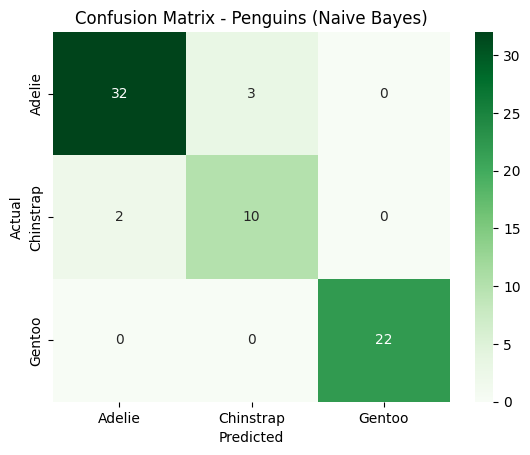

In [7]:
nb = GaussianNB()
nb.fit(X2_train, y2_train)
y2_pred = nb.predict(X2_test)

print("Accuracy:", accuracy_score(y2_test, y2_pred))
print(classification_report(y2_test, y2_pred))

cm = confusion_matrix(y2_test, y2_pred, labels=nb.classes_)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=nb.classes_, yticklabels=nb.classes_)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix - Penguins (Naive Bayes)')
plt.show()

In [8]:
new_penguin = pd.DataFrame({'Culmen Length (mm)': [47.0], 'Culmen Depth (mm)': [15.0],
                            'Flipper Length (mm)': [215], 'Body Mass (g)': [5000]})
print("Prediction:", nb.predict(new_penguin)[0])
print("Probability:", nb.classes_, nb.predict_proba(new_penguin)[0].round(3))

Prediction: Gentoo
Probability: ['Adelie' 'Chinstrap' 'Gentoo'] [0. 0. 1.]


## Summary

This project uses data from 342 penguins. The data shows 4 body measurements of each penguin. There are 3 kinds of penguins.

Naive Bayes uses the measurements to guess the kind of penguin. The model was right 93% of the time.

Gentoo penguins were all correct. A few Adelie and Chinstrap penguins were mixed up.

Dataset Source

Kaggle – Palmer Penguins

https://www.kaggle.com/datasets/malanep/palmer-penguine